# Session 4, simulating Type I and Type II error

> **"Innocent until proven guilty" is a null hypothesis. A courtroom can still get it wrong two ways.**

Type I and Type II error are definitions until you watch them happen. This notebook runs the same test thousands of times in a loop, once when the null is actually true and once when it is actually false, and counts how often each mistake occurs. The same simulation engine is then pointed at a courtroom, a manufacturing batch, and a sales promotion, because the mechanics are identical. All that changes is the costume.

## Step 1, one reusable test-simulator

`run_many_tests` draws `n_sims` samples of size `n` from a population with true mean `mu_true`, runs a one-sample t-test of `H0: mu = mu0` against each sample at the given `alpha`, and reports the fraction of samples that reject H0.

- Feed it `mu_true = mu0` (the null is actually true) and the rejection rate estimates **alpha**, the Type I error rate, directly.
- Feed it `mu_true != mu0` (the null is actually false) and the rejection rate estimates **power** (1 minus beta); the rate it *fails* to reject is the Type II error rate, beta.

In [1]:
import numpy as np
from scipy import stats

rng = np.random.default_rng(7)

def run_many_tests(mu_true, mu0, sd, n, alpha=0.05, n_sims=5000, alternative='two-sided'):
    samples = rng.normal(mu_true, sd, size=(n_sims, n))
    t_stat, p_value = stats.ttest_1samp(samples, popmean=mu0, axis=1, alternative=alternative)
    rejected = p_value < alpha
    return rejected.mean()

print('simulator ready')

simulator ready


## Step 2, the courtroom: how often do we convict the innocent?

Imagine a crude "guilt score" that should average 0 for a truly innocent defendant, with some natural noise from witness error, forensic variation, and so on. We test H0: the defendant is innocent (mean guilt score = 0) at alpha = 0.05, over and over, on defendants who are *actually* innocent every time.

In [2]:
alpha = 0.05
type_I_rate = run_many_tests(mu_true=0.0, mu0=0.0, sd=1.0, n=20, alpha=alpha, alternative='greater')
print(f'alpha set to          {alpha:.3f}')
print(f'simulated Type I rate  {type_I_rate:.3f}  (should land close to alpha)')
print()
print('Every one of these "convictions" is a false alarm: an innocent defendant, wrongly found guilty,')
print('purely because the evidence happened to look incriminating by chance. Setting alpha IS setting')
print('how often a justice system is willing to do this.')

alpha set to          0.050
simulated Type I rate  0.055  (should land close to alpha)

Every one of these "convictions" is a false alarm: an innocent defendant, wrongly found guilty,
purely because the evidence happened to look incriminating by chance. Setting alpha IS setting
how often a justice system is willing to do this.


## Step 3, the courtroom: how often do we acquit the guilty?

Now simulate defendants who are *actually* guilty: their true average guilt score sits above 0. Run the identical test and identical alpha. The rejection rate is the test's **power**, the chance of correctly convicting; the miss rate (1 minus power) is beta, the Type II rate.

In [3]:
effect = 0.6   # how much the guilty defendants' true guilt score sits above 0
power = run_many_tests(mu_true=effect, mu0=0.0, sd=1.0, n=20, alpha=alpha, alternative='greater')
beta = 1 - power
print(f'power (correct conviction rate) = {power:.3f}')
print(f'beta (Type II / acquit the guilty) = {beta:.3f}')
print()
print('Try it again with a smaller n, or a smaller effect (weaker evidence): beta climbs. A test')
print('starved of data or facing a subtle effect misses real guilt more often, not less.')

power (correct conviction rate) = 0.837
beta (Type II / acquit the guilty) = 0.163

Try it again with a smaller n, or a smaller effect (weaker evidence): beta climbs. A test
starved of data or facing a subtle effect misses real guilt more often, not less.


## Step 4, the same engine on a manufacturing batch

H0: the batch meets spec (true mean diameter = the 25.00mm target). Type I here is **producer's risk**: a perfectly good batch gets rejected. Type II is **consumer's risk**: a batch that has actually drifted off target gets accepted and shipped.

In [4]:
target, tol = 25.00, 0.05

producers_risk = run_many_tests(mu_true=target, mu0=target, sd=0.09, n=36, alpha=alpha, alternative='two-sided')
print(f"producer's risk (Type I, reject a good batch)   = {producers_risk:.3f}")

drift = 0.045   # the true mean has drifted this far from target, still inside the +/-0.05mm spec
consumers_risk = 1 - run_many_tests(mu_true=target + drift, mu0=target, sd=0.09, n=36, alpha=alpha, alternative='two-sided')
print(f"consumer's risk (Type II, miss a drifted batch) = {consumers_risk:.3f}")
print()
print('A drift of 0.045mm is still inside the 0.05mm spec tolerance, so it is a genuinely subtle')
print('shift. A consumer-risk this far above the 5 percent alpha is the point: small, real drifts')
print('are easy to miss with a modest sample, which is why QC sampling plans specify a minimum n.')

producer's risk (Type I, reject a good batch)   = 0.051
consumer's risk (Type II, miss a drifted batch) = 0.162

A drift of 0.045mm is still inside the 0.05mm spec tolerance, so it is a genuinely subtle
shift. A consumer-risk this far above the 5 percent alpha is the point: small, real drifts
are easy to miss with a modest sample, which is why QC sampling plans specify a minimum n.


## Step 5, the same engine on a sales promotion

H0: the promotion has no effect (true mean daily sales = the 1,200 benchmark). Type I is rolling out a promotion that does nothing; Type II is shelving one that actually works.

In [5]:
benchmark = 1200.0

false_rollout_rate = run_many_tests(mu_true=benchmark, mu0=benchmark, sd=120, n=25, alpha=alpha, alternative='greater')
print(f'Type I: roll out a promotion that does nothing    = {false_rollout_rate:.3f}')

true_lift = 45.0   # a real but modest sales lift
missed_promo_rate = 1 - run_many_tests(mu_true=benchmark + true_lift, mu0=benchmark, sd=120, n=25, alpha=alpha, alternative='greater')
print(f'Type II: shelve a promotion that really lifted sales = {missed_promo_rate:.3f}')
print()
print('Compare this to Part C\'s worked sales example, where the observed lift was 65 on a sample')
print('of 25 and the test rejected comfortably. A smaller true lift, like the 45 here, is caught')
print('far less reliably at the same sample size: that gap IS beta.')

Type I: roll out a promotion that does nothing    = 0.049
Type II: shelve a promotion that really lifted sales = 0.437

Compare this to Part C's worked sales example, where the observed lift was 65 on a sample
of 25 and the test rejected comfortably. A smaller true lift, like the 45 here, is caught
far less reliably at the same sample size: that gap IS beta.


## Step 6, what alpha actually buys you

Sweep alpha and watch both error rates move. Raising alpha always buys lower beta (easier to detect a real effect), at the cost of a higher Type I rate. There is no free lunch, only a trade you get to choose, out loud, before you look at the data.

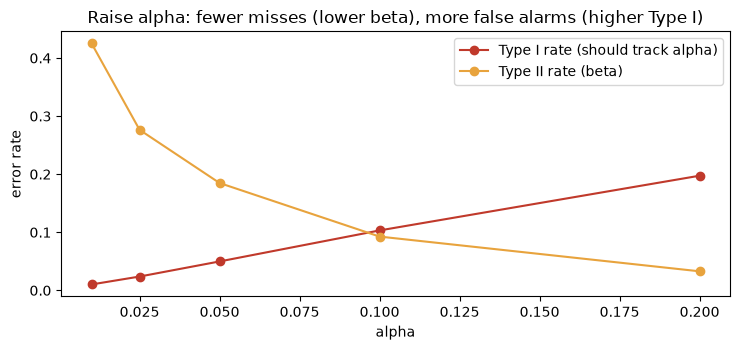

In [6]:
import matplotlib.pyplot as plt

alphas = np.array([0.01, 0.025, 0.05, 0.10, 0.20])
type_I = [run_many_tests(mu_true=0.0, mu0=0.0, sd=1.0, n=20, alpha=a, alternative='greater') for a in alphas]
power_at = [run_many_tests(mu_true=0.6, mu0=0.0, sd=1.0, n=20, alpha=a, alternative='greater') for a in alphas]
beta_at = [1 - p for p in power_at]

plt.figure(figsize=(7.5, 3.6))
plt.plot(alphas, type_I, 'o-', color='#C0392B', label='Type I rate (should track alpha)')
plt.plot(alphas, beta_at, 'o-', color='#E8A33D', label='Type II rate (beta)')
plt.xlabel('alpha'); plt.ylabel('error rate'); plt.legend()
plt.title('Raise alpha: fewer misses (lower beta), more false alarms (higher Type I)')
plt.tight_layout(); plt.show()

## Your call

Jot down, and push Claude on:
1. In the courtroom simulation, the Type I rate landed close to alpha but not exactly on it. Why would it never be exact, even with a huge number of simulated trials?
2. Which number in Step 4 would you show a plant manager who wants to cut the sample size to save cost? Why?
3. In Step 6's chart, pick an alpha you would actually set for the sales promotion case, and justify it from the relative cost of a wasted rollout versus a missed lift.
4. The courtroom, the factory and the sales team all ran through the identical `run_many_tests` function. What does that tell you about what a hypothesis test actually is, underneath the vocabulary?